# OpenCV - Blending

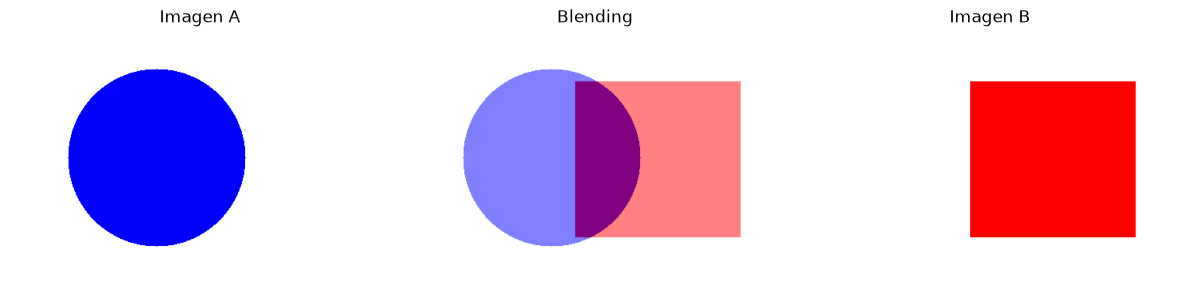

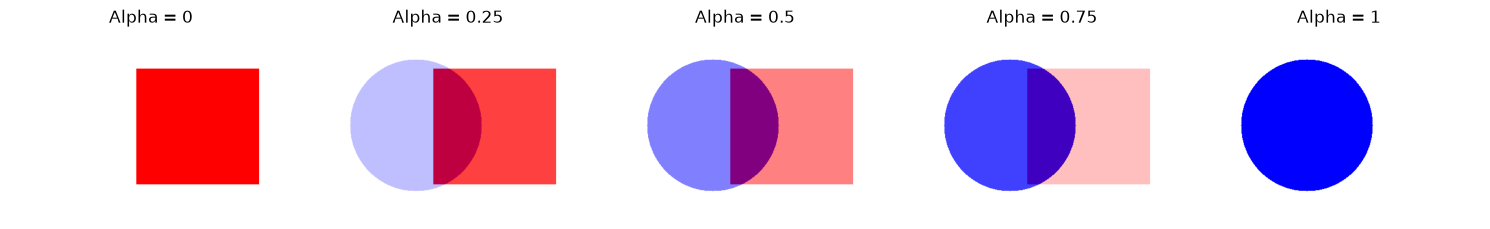

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CREAR DOS IMÁGENES DEL MISMO TAMAÑO
# ============================================================
img1 = np.full((320, 480, 3), 255, dtype=np.uint8)
img2 = np.full_like(img1, 255)

# Dibujar un círculo azul en la primera imagen (BGR)
cv2.circle(img1, (185, 160), 112, (255, 0, 0), -1)

# Dibujar un rectángulo rojo en la segunda imagen (BGR)
cv2.rectangle(img2, (215, 64), (423, 260), (0, 0, 255), -1)

# ============================================================
# 2. APLICAR BLENDING
# ============================================================
alpha = 0.5
beta = 1 - alpha
gamma = 0

img_blend = cv2.addWeighted(img1, alpha, img2, beta, gamma)

# ============================================================
# 3. VISUALIZAR LAS IMÁGENES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

images = [img1, img_blend, img2]
titles = ["Imagen A", "Blending", "Imagen B"]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 4. PROBAR DIFERENTES VALORES DE ALPHA
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for ax, alpha in zip(axes, [0, 0.25, 0.5, 0.75, 1]):
    result = cv2.addWeighted(img1, alpha, img2, 1 - alpha, 0)
    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Alpha = {alpha}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# OpenCV - Deteccion de bordes

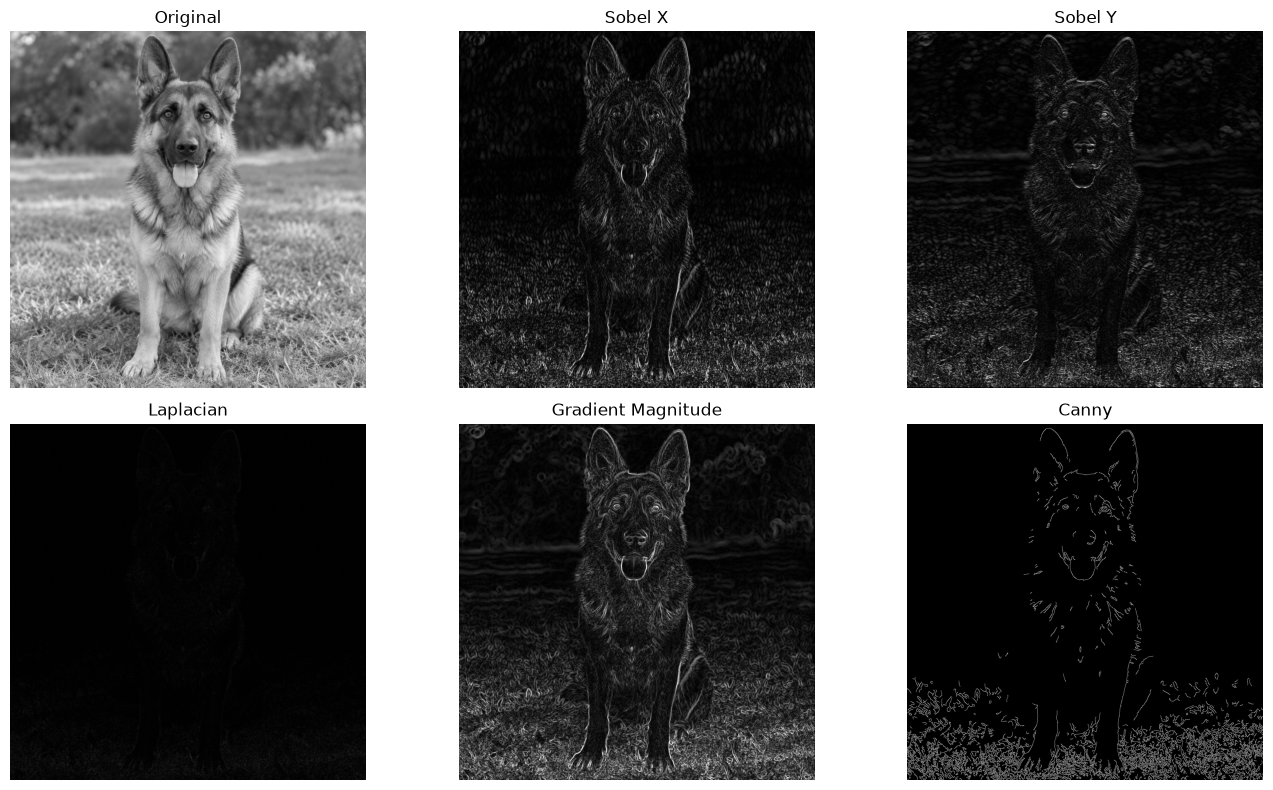

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CARGAR IMAGEN JPG EN ESCALA DE GRISES
# ============================================================
img = cv2.imread("resources/dogs/dog1.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("No se encontró resources/dogs/dog1.png")

# ============================================================
# 2. REDUCIR RUIDO
# ============================================================
blurred = cv2.GaussianBlur(img, (5, 5), 0)

# ============================================================
# 3. DETECTAR BORDES CON SOBEL
# ============================================================
sobel_x = cv2.Sobel(
    blurred, cv2.CV_64F, 1, 0, ksize=3
)

sobel_y = cv2.Sobel(
    blurred, cv2.CV_64F, 0, 1, ksize=3
)

# ============================================================
# 4. DETECTAR BORDES CON LAPLACIAN
# ============================================================
laplacian = cv2.Laplacian(
    blurred, cv2.CV_64F
)

# ============================================================
# 5. MAGNITUD DEL GRADIENTE
# ============================================================
magnitude = cv2.magnitude(sobel_x, sobel_y)

# ============================================================
# 6. DETECTAR BORDES CON CANNY
# ============================================================
canny = cv2.Canny(
    blurred,
    threshold1=80,
    threshold2=160
)

# ============================================================
# 7. PREPARAR RESULTADOS
# ============================================================
images = [
    img,
    cv2.convertScaleAbs(sobel_x),
    cv2.convertScaleAbs(sobel_y),
    cv2.convertScaleAbs(laplacian),
    cv2.convertScaleAbs(magnitude),
    canny
]

titles = [
    "Original",
    "Sobel X",
    "Sobel Y",
    "Laplacian",
    "Gradient Magnitude",
    "Canny"
]

# ============================================================
# 8. VISUALIZAR COMPARACIÓN
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Deteccion de Caras

Resolución procesada: (1067, 1600, 3)
Detecciones: 3
Detección 1: Confianza=95.62%, Posición=(725, 273), Tamaño=(162, 218)
Detección 2: Confianza=94.48%, Posición=(1170, 125), Tamaño=(183, 243)
Detección 3: Confianza=94.05%, Posición=(225, 162), Tamaño=(191, 293)


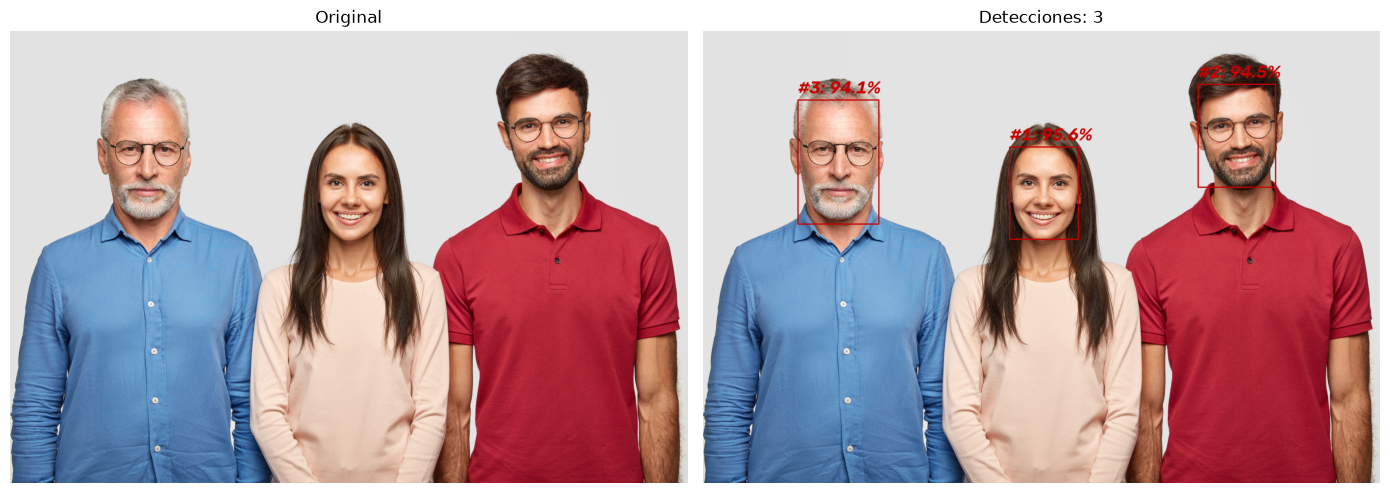

Resultado guardado en: tmp\people_detected.jpg


In [49]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
import hashlib

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================
TMP_DIR = Path("tmp")
TMP_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_PATH = Path("test_images/people.jpg")
MODEL_PATH = TMP_DIR / "face_detection_yunet_2026may.onnx"
OUTPUT_PATH = TMP_DIR / "people_detected.jpg"

CONFIDENCE_THRESHOLD = 0.6
NMS_THRESHOLD = 0.1

# ============================================================
# 2. DESCARGAR MODELO ONNX SI NO EXISTE
# ============================================================
MODEL_URL = (
    "https://media.githubusercontent.com/media/"
    "opencv/opencv_zoo/main/models/face_detection_yunet/"
    "face_detection_yunet_2026may.onnx"
)

EXPECTED_SHA256 = (
    "ebafce4e3c118d6554634be5c27ab333b"
    "4c047a9a8c3faf1d7cf93101c22f0f0"
)

def valid_model(path):
    if not path.exists():
        return False
    checksum = hashlib.sha256(path.read_bytes()).hexdigest()
    return checksum == EXPECTED_SHA256

if not valid_model(MODEL_PATH):
    print("Descargando modelo YuNet...")
    urlretrieve(MODEL_URL, MODEL_PATH)

if not valid_model(MODEL_PATH):
    MODEL_PATH.unlink(missing_ok=True)
    raise ValueError("El modelo descargado no es válido")

# ============================================================
# 3. CARGAR Y REDIMENSIONAR IMAGEN
# ============================================================
img = cv2.imread(str(IMAGE_PATH))

if img is None:
    raise FileNotFoundError(f"No se encontró: {IMAGE_PATH}")

h, w = img.shape[:2]

# Reducir resolución manteniendo las proporciones
max_size = 1600
scale = min(1.0, max_size / max(w, h))

new_w = round(w * scale)
new_h = round(h * scale)

img = cv2.resize(
    img,
    (new_w, new_h),
    interpolation=cv2.INTER_AREA
)

h, w = img.shape[:2]

print("Resolución procesada:", img.shape)

# ============================================================
# 4. CREAR DETECTOR YUNET
# ============================================================
detector = cv2.FaceDetectorYN.create(
    model=str(MODEL_PATH),
    config="",
    input_size=(w, h),
    score_threshold=0.70,
    nms_threshold=0.1,
    top_k=5000
)

# ============================================================
# 5. DETECTAR ROSTROS
# ============================================================
_, faces = detector.detect(img)

result = img.copy()

if faces is None:
    faces = []

print("Detecciones:", len(faces))

# ============================================================
# 6. INSPECCIONAR Y DIBUJAR DETECCIONES
# ============================================================
for i, face in enumerate(faces):

    x, y, width, height = face[:4].astype(int)
    confidence = float(face[-1])

    print(
        f"Detección {i + 1}: "
        f"Confianza={confidence:.2%}, "
        f"Posición=({x}, {y}), "
        f"Tamaño=({width}, {height})"
    )

    startX = max(0, x)
    startY = max(0, y)
    endX = min(w, x + width)
    endY = min(h, y + height)

    if endX <= startX or endY <= startY:
        continue

    cv2.rectangle(
        result,
        (startX, startY),
        (endX, endY),
        (0, 0, 200),
        2
    )

    cv2.putText(
        result,
        f"#{i + 1}: {confidence:.1%}",
        (startX, max(startY - 15, 15)),
        cv2.FONT_HERSHEY_SCRIPT_COMPLEX,
        1.5,
        (0, 0, 200),
        2
    )

# ============================================================
# 7. VISUALIZAR RESULTADOS
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, image, title in zip(
    axes,
    [img, result],
    ["Original", f"Detecciones: {len(faces)}"]
):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 8. GUARDAR RESULTADO
# ============================================================
cv2.imwrite(str(OUTPUT_PATH), result)
print("Resultado guardado en:", OUTPUT_PATH)